# Quiz 6

PCA and k-NN on a 214-row chemical-composition dataset with a Type label (quiz6-data.csv): the share of variance of the first principal component, the information lost with 4 components, the accuracy and recall of 3-NN on rows 50 to 89 (trained on the other rows), and the 3-NN accuracy after reconstructing the data from 1 to 9 components.

In [1]:
import pandas as pd
data = pd.read_csv("./quiz6-data.csv", sep=",")

In [2]:
trainingRange = list(range(0, 50)) + list(range(90,146))
training = data.loc[trainingRange, :]
trainingType = training.loc[:, "Type"]
training = training.drop(["Type"], axis=1)

In [3]:
testingRange = list(range(50, 90))
testing = data.loc[testingRange, :]
testingType = testing.loc[:, "Type"]
testing = testing.drop("Type", axis=1)

In [4]:
# training = training.drop_duplicates()

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
scaler = StandardScaler()
scaler = scaler.fit(training)
transformed = pd.DataFrame(scaler.transform(training), columns=training.columns)
scaler = scaler.fit(testing)
transformedTesting = pd.DataFrame(scaler.transform(testing), columns=testing.columns)
pca = PCA()
pca = pca.fit(transformed)
pca_transformed = pca.transform(transformed)
eigenvalues = pca.explained_variance_
eigenvectors = pca.components_

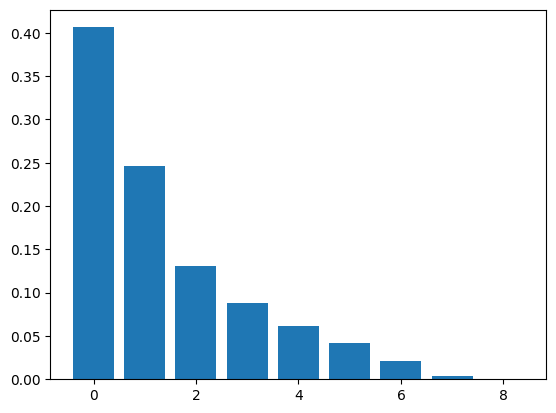

In [5]:
import matplotlib.pyplot as plt
plt.bar(range(len(eigenvalues)), eigenvalues/sum(eigenvalues))
plt.show()

question 1

In [6]:
print(eigenvalues[0]/sum(eigenvalues))

0.40636040093776327


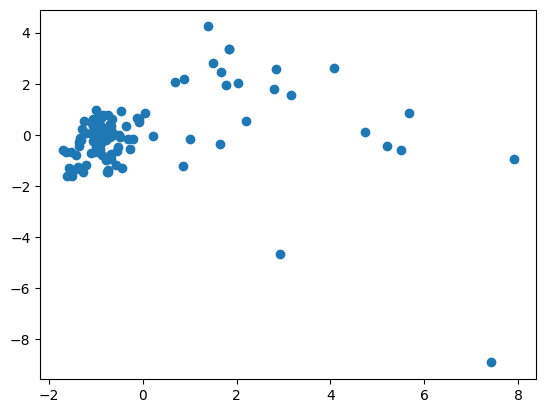

In [7]:
pca = PCA(n_components=4)
pca = pca.fit(transformed)
pca_transformed = pd.DataFrame(pca.transform(transformed))
plt.scatter(pca_transformed.loc[:, 0], pca_transformed.loc[:, 1])
plt.show()

In [8]:
pca_inverse = pd.DataFrame(pca.inverse_transform(pca_transformed.to_numpy()), columns=training.columns)

question 2

In [9]:
info_loss = 1 - (eigenvalues[0] + eigenvalues[1] + eigenvalues[2] + eigenvalues[3])/sum(eigenvalues)  
print(info_loss)

0.12801476071848472


question 3

In [10]:
from sklearn.neighbors import KNeighborsClassifier
clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(training, trainingType)
pred = clf.predict(testing)

In [11]:
from sklearn.metrics import accuracy_score, recall_score
print(accuracy_score(testingType, pred))

0.775


question 4

In [12]:
print(recall_score(testingType,pred))

0.75


question 5

In [13]:
import numpy as np
testing_error = [ 0 for i in range(len(eigenvalues)+1)]
for i in range(1,len(eigenvalues)+1):
    pca = PCA(n_components=i)
    pca = pca.fit(transformed)
    pca_transformed = pd.DataFrame(pca.transform(transformed))
    pca_inverse = pd.DataFrame(pca.inverse_transform(pca_transformed.to_numpy()), columns=training.columns)
    clf = KNeighborsClassifier(n_neighbors=3).fit(pca_inverse,trainingType)
    pca = pca.fit(transformedTesting)
    pca_transformed_testing = pca.transform(transformedTesting)
    pca_inverse_testing = pd.DataFrame(pca.inverse_transform(pca_transformed_testing), columns=testing.columns)
    pred = clf.predict(pca_inverse_testing)
    testing_error[i] = accuracy_score(testingType, pred)
    

In [14]:
print(testing_error)

[0, 0.525, 0.3, 0.5, 0.45, 0.65, 0.725, 0.725, 0.725, 0.725]
